# 응용 모의 제4회 풀이

공정 수율과 불량 검출

공식 정답이 아닌 실제 실행 예시 답안입니다. PDF와 지문이 동일합니다. 각 문항의 가정·가설·실제 수치·판단을 함께 읽고 src 모듈 및 공통 analysis.py를 참조하십시오.

In [1]:
from pathlib import Path
import sys
FOLDER=Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
sys.path.insert(0,str(FOLDER.parent/'공통'))
from analysis import Context
ctx=Context(FOLDER)


## 1. 회귀 설계와 조건별 개선

부하가 큰 배치에서 수율 오차 변동 폭이 커질 수 있다. 알려진 분산은 없으며 학습 잔차에서 추정하는 분산 모형은 불확실성을 가진다. regression.csv의240행은 서로 독립인 개체/배치을 가정한 고정 합성 자료다. 목표 target의 단위는 수율 점수이며 id는 식별자다. 입력은 load, pressure, temperature, speed다. 입력은 고정 업무 기준 대비 편차 지수이므로 음수가 가능하며 표본 전체에서 미리 추정한 표준화 값이 아니다. 시드20270004로 학습70%/최종평가30% 분할하고 학습 shuffled3-fold를 사용한다. 후보 선택 기준은 동일 원반응 단위 CV R² 최대다. 기본 대치·표준화·선형 모형, VIF5, AIC/BIC 후진 선택과 학습 분산 추정의 가중 회귀1·2회 후보를 사전 지정한다. 모든 학습 통계·변수선택·행 처리는 폴드 안에서 적합한다. 유의수준은5%이며 반복 진단은 탐색적 개별검정으로 보고한다. 최종평가로 후보나 가정을 골라서는 안 된다.

### 1-1

**문제 (6점)** 관측 단위·목표 척도·예측 시점과 입력의 역할을 정리하고 결측·분포·공선성 후보를 탐색하시오. 지정 분할의 원행 위치를 남기고 전체 자료 대치나 식별자 입력이 왜 부적절한지 설명하시오.

**선택 근거·가정·해석**

원행 위치를 먼저 봉인하고 결측 대치·스케일·선택은 Pipeline.fit 안에 둔다. id는 의미 없는 식별자이며 test는 최종 보고만 한다.

In [2]:
ctx.run('1-1','reg_design')

{'n': 240,
 'feature_names': ['load', 'pressure', 'temperature', 'speed'],
 'missing': {'load': 0, 'pressure': 8, 'temperature': 0, 'speed': 0},
 'train_indices': [0,
  1,
  2,
  3,
  5,
  7,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  35,
  36,
  39,
  40,
  41,
  44,
  45,
  46,
  47,
  49,
  50,
  52,
  53,
  54,
  58,
  59,
  61,
  63,
  65,
  67,
  69,
  70,
  71,
  72,
  73,
  74,
  76,
  77,
  78,
  80,
  81,
  82,
  83,
  84,
  88,
  89,
  90,
  93,
  94,
  95,
  96,
  97,
  99,
  100,
  105,
  106,
  109,
  110,
  112,
  114,
  115,
  116,
  117,
  119,
  120,
  121,
  122,
  125,
  126,
  127,
  128,
  129,
  130,
  132,
  133,
  134,
  135,
  136,
  137,
  138,
  139,
  141,
  143,
  144,
  148,
  149,
  150,
  151,
  153,
  154,
  156,
  157,
  158,
  160,
  161,
  162,
  164,
  166,
  167,
  168,
  169,
  170,
  171,
  172,
  173,
  174,
  175,
  177,
  179,
  180,
  182,
 

### 1-2

**문제 (6점)** 기본 전처리와 선형 기준 모형을 학습에 적합하고 학습/CV R², 계수 t 검정·전체 F 검정·AIC·BIC를 제시하시오. 계수·설명력·일반화 성능의 의미와 기본 추론 가정을 구분하시오. 최종평가는 아직 사용하지 마시오.

**선택 근거·가정·해석**

R²와 수정 R²는 적합 설명력, CV R²는 학습 밖 예측 평가다. t는 개별 계수, F는 지정 전체 기울기 가설이다. 고전적 추론은 올바른 사양·독립·등분산·정규 오차에 조건부이며 y 자체 정규성을 요구하지 않는다.

In [3]:
ctx.run('1-2','reg_baseline')

{'train': {'r2': 0.8598148841673794,
  'rmse': 0.8051546885203349,
  'mae': 0.5736769955563112},
 'cv_r2': 0.8460115304446235,
 'coefficients': {'columns': ['term',
   'coefficient',
   'standard_error',
   't_statistic',
   'p_value',
   'ci_lower',
   'ci_upper',
   'reject_h0'],
  'index': [0, 1, 2, 3, 4],
  'data': [['Intercept',
    5.055511875078572,
    0.0630645823640351,
    80.16404272521852,
    7.22074489553168e-133,
    4.930982998031587,
    5.180040752125557,
    True],
   ['numeric__load',
    2.427397289667448,
    0.5286059502531012,
    4.5920733364904205,
    8.732916058241544e-06,
    1.3835989655083547,
    3.471195613826541,
    True],
   ['numeric__pressure',
    -0.44819620618239614,
    0.0635926858509793,
    -7.047920687493562,
    4.868864549962861e-11,
    -0.573767889377119,
    -0.3226245229876733,
    True],
   ['numeric__temperature',
    -0.43084878295450135,
    0.5285174607850659,
    -0.8152025522761607,
    0.41614591730074657,
    -1.474472373631

### 1-3

**문제 (6점)** 기준 모형의 선형 사양·잔차 정규성·등분산성과 관측 설계에 맞는 독립성/자기상관을 진단하시오. 가설·통계량·p값·가정·판정과 잔차/분위수/영향도 그림을 보고하시오. VIF와 Cook 영향도의 대상을 구분하고 이상 관측을 자동으로 오류라고 단정하지 마시오.

**선택 근거·가정·해석**

정규성은 적합 잔차의 JB, 사양은 RESET, 등분산은 Koenker/BP를 사용한다. IID의 DW는 기술값만, 명시 시간순은 BG를 사용한다. 가설을 각각 분리하고 탐색적 개별 p값을 해석한다. VIF는 설계 열, Cook은 관측의 추정 영향이며 비기각은 가정 증명이 아니다.

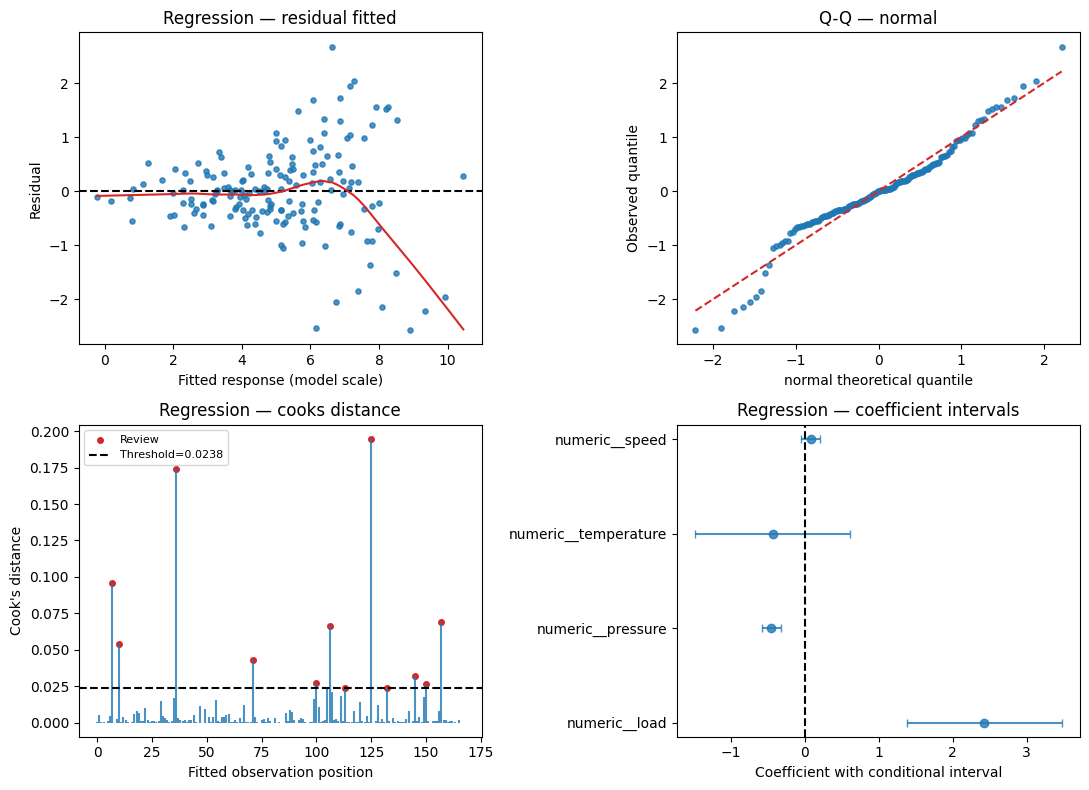

{'tests': {'normality': {'tests': {'columns': ['test',
     'statistic',
     'p_value',
     'reject_h0',
     'df_num',
     'df_den'],
    'index': [0],
    'data': [['jarque_bera',
      22.110314875404782,
      1.5805423178128148e-05,
      True,
      None,
      None]]},
   'details': {'n_samples': 168, 'hypothesis': '정규 오차'},
   'parameters': {'alpha': 0.05, 'method': 'jarque_bera'},
   'warnings': ['반응변수 y가 아닌 잔차를 검사합니다. 적합 잔차의 의존성 때문에 iid 표본 검정의 p를 단독 확정 기준으로 쓰지 않습니다.']},
  'linearity': {'tests': {'columns': ['test',
     'statistic',
     'p_value',
     'reject_h0',
     'df_num',
     'df_den'],
    'index': [0],
    'data': [['RESET F',
      4.11276870534871,
      0.0181124797322444,
      True,
      2.0,
      161.0]]},
   'details': {'n_samples': 168, 'hypothesis': '해당 대안 대비 선형 사양이 적절함'},
   'parameters': {'alpha': 0.05,
    'method': 'reset',
    'power': 3,
    'fraction': 0.5},
   'warnings': ['비기각은 선형성의 증명이 아닙니다. RESET는 누락변수/함수형 등 다른 사양 오류에도 반응하고 Rainbow는 행 순서·등

In [4]:
ctx.run('1-3','reg_diagnostics')

### 1-4

**문제 (6점)** 동일 학습 행·동일 원반응에서 AIC와 BIC로 후진 변수선택을 수행하고 제거 경로·남은 특성을 비교하시오. VIF 제거와의 차이, 서로 다른 y변환·관측 행의 정보량을 직접 비교하는 오류, 변수선택 후 추론의 한계를 설명하시오.

**선택 근거·가정·해석**

AIC=-2ll+2k, BIC=-2ll+log(n)k의 감소를 따라 탐욕적 후진 선택한다. 같은 행/반응의 비교다. 최적 부분집합 보장이나 선택 후 추론 보정은 없으며 CV 폴드에서 다시 선택해야 한다.

In [5]:
ctx.run('1-4','reg_selection')

{'aic': {'selected_features': ['numeric__load', 'numeric__pressure'],
  'history': {'columns': ['step', 'removed', 'aic', 'bic', 'accepted'],
   'index': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
   'data': [[0, None, 413.94513807201827, 429.56495796903454, True],
    [1, 'numeric__load', 432.38385313328354, 444.87970905089657, False],
    [1, 'numeric__pressure', 456.63422144578027, 469.1300773633933, False],
    [1, 'numeric__temperature', 412.62868592592935, 425.1245418435424, True],
    [1, 'numeric__speed', 413.646931512165, 426.142787429778, False],
    [2, 'numeric__load', 738.575557347802, 747.9474492860118, False],
    [2, 'numeric__pressure', 455.14845644444443, 464.5203483826542, False],
    [2, 'numeric__speed', 412.27332997990646, 421.64522191811625, True],
    [3, 'numeric__load', 736.6598368033367, 742.9077647621432, False],
    [3, 'numeric__pressure', 454.09229395662885, 460.3402219154354, False]]},
  'parameters': {'criterion': 'aic',
   'min_features': 1,
   'max_steps': 30,
 

### 1-5

**문제 (6점)** 사전 지정 전처리·변수선택·대안 모형을 학습 CV 내부에서 튜닝하시오. 후보별 원단위 CV R²·선택 파라미터·실패 여부와 분할을 보고하고 하나를 선택하시오. 특히 학습 분산 추정의 가중 회귀1·2회 후보의 적용 조건과 처리 단위를 설명하시오.

**선택 근거·가정·해석**

원단위 CV R² 최대를 선택하며 후보별 clone은 각 학습 폴드에서 모든 처리를 새로 적합한다. 기준 대비 진단과 점수를 함께 보고 test로 모델을 바꾸지 않는다. 가중치는 참 분산을 알고 지정한 값이 아니다. 추정 역분산·가중 잔차·원단위 R²를 구분하고 조건부 표준오차가 분산 추정 불확실성을 반영하지 않음을 밝힌다.

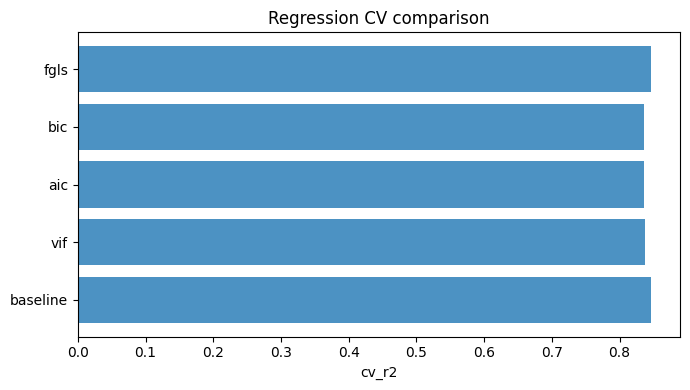

{'comparison': {'columns': ['name', 'cv_r2', 'best_params'],
  'index': [0, 1, 2, 3, 4],
  'data': [['baseline', 0.8460115304446235, {'degree': 1}],
   ['vif', 0.8372367790451927, {'degree': 1}],
   ['aic', 0.8361602888151811, {'degree': 1}],
   ['bic', 0.8364392162326301, {'degree': 1}],
   ['fgls', 0.8468544845175501, {'iterations': 1}]]},
 'selected_name': 'fgls',
 'folds': [{'train_indices': [0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    14,
    15,
    16,
    17,
    18,
    20,
    21,
    22,
    23,
    24,
    25,
    28,
    29,
    30,
    32,
    33,
    36,
    39,
    40,
    41,
    42,
    43,
    44,
    46,
    48,
    49,
    50,
    52,
    53,
    54,
    57,
    60,
    61,
    66,
    67,
    69,
    70,
    71,
    76,
    77,
    78,
    80,
    81,
    82,
    83,
    85,
    86,
    87,
    88,
    89,
    91,
    92,
    93,
    94,
    95,
    96,
    100,
    102,
    103,
    105,
    106,
    108,
    110,

In [6]:
ctx.run('1-5','reg_tuning')

### 1-6

**문제 (6점)** 선택 이후에만 기준/선택 모형을 동일 최종평가 행으로 평가하여 R²·RMSE·MAE와 R² 차이를 보고하시오. 진단 전후 또는 대안 분포의 적절한 잔차·분산·영향도 근거를 해석하고, 개선이 없거나 가정 위반이 남아도 그대로 보고하시오. 가중치는 참 분산을 알고 지정한 값이 아니다. 추정 역분산·가중 잔차·원단위 R²를 구분하고 조건부 표준오차가 분산 추정 불확실성을 반영하지 않음을 밝힌다.

**선택 근거·가정·해석**

같은 보류 원행에서 기준/선택 점수를 계산하고 ΔR²=선택-기준을 그대로 보고한다. 개선이나 모든 가정 만족을 보장하지 않는다. 가중치는 참 분산을 알고 지정한 값이 아니다. 추정 역분산·가중 잔차·원단위 R²를 구분하고 조건부 표준오차가 분산 추정 불확실성을 반영하지 않음을 밝힌다.

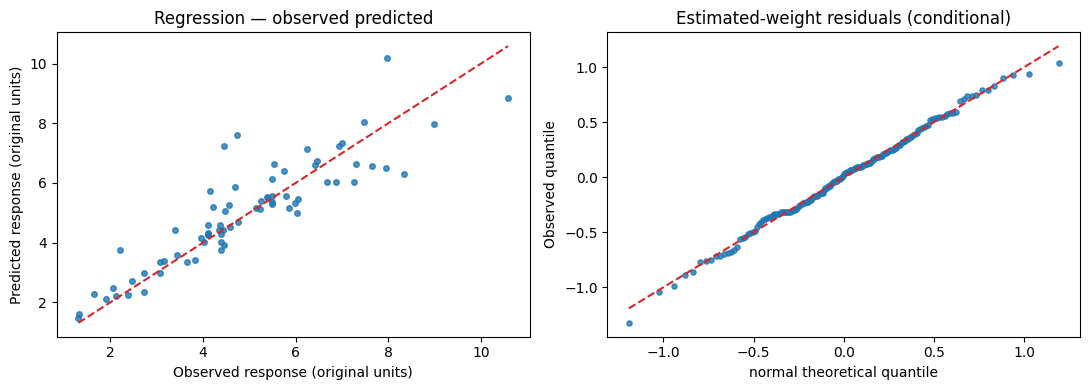

{'selected_name': 'fgls',
 'baseline_test': {'r2': 0.7922845364358704,
  'rmse': 0.848879750916605,
  'mae': 0.5953852654358529},
 'selected_test': {'r2': 0.7879234560706838,
  'rmse': 0.8577447690395714,
  'mae': 0.5928177460814299},
 'delta_r2': -0.004361080365186565,
 'test_indices': [4,
  6,
  8,
  26,
  34,
  37,
  38,
  42,
  43,
  48,
  51,
  55,
  56,
  57,
  60,
  62,
  64,
  66,
  68,
  75,
  79,
  85,
  86,
  87,
  91,
  92,
  98,
  101,
  102,
  103,
  104,
  107,
  108,
  111,
  113,
  118,
  123,
  124,
  131,
  140,
  142,
  145,
  146,
  147,
  152,
  155,
  159,
  163,
  165,
  176,
  178,
  181,
  183,
  185,
  186,
  190,
  194,
  195,
  197,
  201,
  206,
  216,
  218,
  220,
  222,
  225,
  226,
  227,
  229,
  231,
  232,
  238],
 'truth': [2.3945203171,
  3.3981857439,
  4.1044414362,
  4.5622603692,
  5.7581432315,
  5.258933861,
  4.3985546612,
  2.0664857368,
  4.032957757,
  4.6885270327,
  3.9495486977,
  4.3881648771,
  7.9397051692,
  4.2134871491,
  4.479

In [7]:
ctx.run('1-6','reg_final')

## 2. 이진 사건 예측과 샘플링

classification.csv는 별도 독립360관측의 합성 자료이며 target=1은 불량 발생이다. c1~c4는 사건 발생 전의 수치 위험 신호, id는 식별자다. 층화 학습70%/최종평가30% 분할(시드20270004), 학습3-fold ROC AUC를 사용한다. 무보완과 smote를 비교하되 학습 폴드 안의 대치→표준화→VIF5→샘플링→L2 로지스틱 예측모형을 사용한다. C 후보는0.1·1·10이고 GridSearchCV 전수비교로 튜닝한다. 운영 임계값0.5는 사전 고정이며 false-negative 비용7·false-positive 비용1이다. 별도로 원 학습 분포의 비벌점 이진 GLM을 설명용 적합하되 예측모형과 같은 추정량이라 주장하지 않는다.

### 2-1

**문제 (8점)** 목표 사건·양성 라벨·클래스 불균형과 층화 분할을 정리하시오. 데이터 분리 전에 샘플을 보완하면 발생하는 누출과 최종평가의 자연 발생률을 유지해야 하는 이유를 설명하시오.

**선택 근거·가정·해석**

층화 분할은 사건 비율을 보존한다. 샘플링은 imblearn Pipeline의 CV fit 내부이며 검증·test는 원 발생률 그대로다. 합성 표본은 원행을 갖는 실제 관측으로 보고하지 않는다.

In [8]:
ctx.run('2-1','cls_design')

{'train_indices': [1,
  3,
  4,
  6,
  7,
  9,
  10,
  11,
  12,
  13,
  15,
  16,
  17,
  19,
  20,
  21,
  22,
  26,
  27,
  28,
  29,
  31,
  32,
  33,
  34,
  35,
  37,
  38,
  39,
  40,
  41,
  42,
  45,
  46,
  47,
  49,
  50,
  51,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  68,
  70,
  72,
  75,
  76,
  78,
  79,
  81,
  82,
  83,
  84,
  85,
  86,
  87,
  88,
  89,
  90,
  91,
  92,
  94,
  98,
  99,
  100,
  101,
  102,
  103,
  106,
  107,
  108,
  110,
  113,
  115,
  116,
  117,
  118,
  119,
  120,
  121,
  122,
  123,
  124,
  126,
  127,
  128,
  129,
  130,
  132,
  136,
  137,
  138,
  139,
  140,
  141,
  142,
  143,
  144,
  145,
  146,
  147,
  150,
  152,
  153,
  154,
  156,
  157,
  159,
  160,
  161,
  162,
  163,
  164,
  165,
  166,
  167,
  169,
  172,
  173,
  174,
  178,
  180,
  181,
  183,
  185,
  186,
  187,
  188,
  189,
  196,
  197,
  198,
  199,
  200,
  201,
  202,
  204,
  205,
  207,
  209,
  210,
  211,
  212

### 2-2

**문제 (8점)** 지정 탐색과 샘플링 모듈을 연결하고 동일 학습 폴드에서 무보완/보완 후보를 비교하시오. 파라미터·CV ROC AUC·선택 후보·폴드 위치를 제시하고 검증/최종평가에는 샘플링을 수행하지 않았음을 확인하시오.

**선택 근거·가정·해석**

동일 폴드 ROC AUC 최대 후보를 선택한다. 대치·스케일·VIF·샘플링을 폴드 안에 둔다. Optuna는 시드·trial 예산·후보 공간을 고정하며 Grid는 지정 후보를 전수 비교한다.

In [9]:
ctx.run('2-2','cls_tuning')

{'method': 'grid',
 'comparison': [{'name': 'none',
   'cv_auc': 0.7682444647774639,
   'best_params': {'model__C': 0.1}},
  {'name': 'smote',
   'cv_auc': 0.7859731449434876,
   'best_params': {'model__C': 0.1}}],
 'selected': 'smote',
 'folds': [{'train_indices': [1,
    2,
    4,
    5,
    7,
    8,
    10,
    11,
    12,
    13,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    37,
    38,
    41,
    42,
    43,
    44,
    45,
    47,
    49,
    52,
    53,
    55,
    56,
    57,
    58,
    59,
    61,
    62,
    63,
    65,
    66,
    68,
    70,
    71,
    72,
    73,
    74,
    75,
    77,
    79,
    80,
    82,
    83,
    84,
    86,
    87,
    89,
    92,
    93,
    94,
    96,
    98,
    99,
    100,
    101,
    102,
    103,
    107,
    110,
    115,
    118,
    119,
    120,
    121,
    123,
    124,
    127,
    129,
    130,
    131,
    132,
    1

### 2-3

**문제 (8점)** 원 학습 분포의 설명용 이진 모형에서 계수·오즈비·구간·z 검정·우도 비교·AIC/BIC를 보고하시오. 첫 선택 특성의 제곱항 추가에 대한 log-odds 사양 검토를 수행하고 가설·자유도·p값·한계를 제시하시오. OLS 잔차 정규성·보통 R²·t/F를 일괄 적용하지 마시오.

**선택 근거·가정·해석**

logit는 성공확률이 아니라 log odds의 선형 사양이다. 자연 발생률의 비벌점 GLM z/우도 추론과 표본보완·L2 예측모형은 별개다. 추가 제곱항의 우도비는 df1 점근 비교이며 비기각이 전체 사양의 증명은 아니다. 오즈비는 확률비·인과효과가 아니다.

In [10]:
ctx.run('2-3','cls_logit')

{'explanatory_model': {'coefficients': {'columns': ['term',
    'coefficient',
    'standard_error',
    'z_statistic',
    'p_value',
    'ci_lower',
    'ci_upper',
    'exp_coefficient'],
   'index': [0, 1, 2, 3],
   'data': [['Intercept',
     -0.9445859628784155,
     0.16484693678845203,
     -5.7300789525170375,
     1.0038390036869692e-08,
     -1.2676800219455324,
     -0.6214919038112986,
     0.38884053199214175],
    ['feature_1',
     -0.8117186427430745,
     0.167343792038067,
     -4.850605049982532,
     1.2308542210001086e-06,
     -1.1397064481740464,
     -0.4837308373121025,
     0.4440941707554584],
    ['feature_2',
     -0.17934690611617182,
     0.16205423022060714,
     -1.106709191559047,
     0.2684196800987968,
     -0.49696736089092425,
     0.1382735486585806,
     0.8358158994510532],
    ['feature_3',
     0.9662650838452269,
     0.17664145488901653,
     5.47020564596419,
     4.495136935922173e-08,
     0.6200541940859978,
     1.312475973604456,
   

### 2-4

**문제 (8점)** CV 선택 뒤 최종평가의 ROC 곡선·ROC AUC·precision-recall·평균정밀도·확률 보정 그림과 Brier 점수, 고정0.5 혼동행렬을 제시하시오. 불균형에서 정확도 하나만으로 판단하는 한계를 설명하시오.

**선택 근거·가정·해석**

같은 최종행과 양성1 확률로 ROC AUC·AP·Brier를 계산한다. AP는 기준 발생률과 함께, 보정 그림은 bin 표본수와 함께 해석한다. 샘플링이 후험확률 보정을 보장하지 않는다.

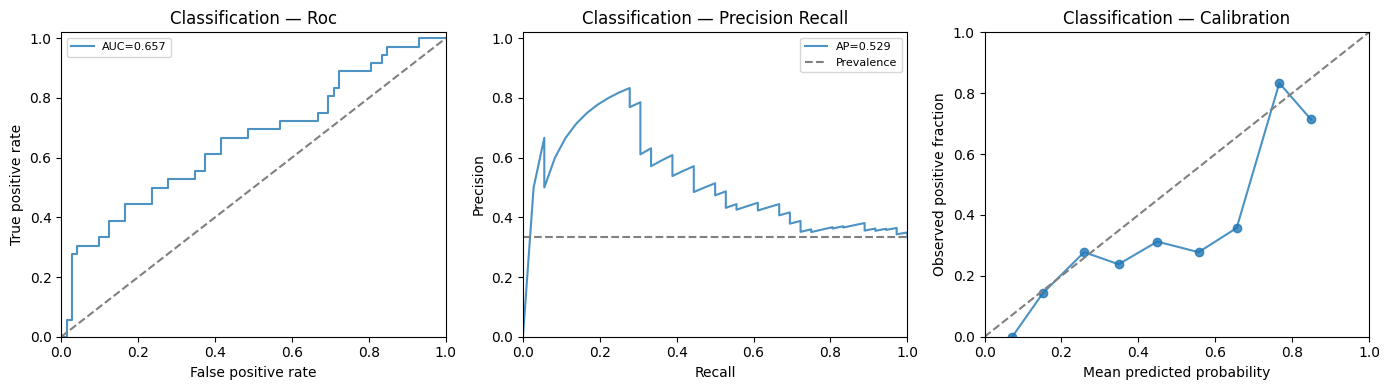

{'selected': 'smote',
 'test_indices': [0,
  2,
  5,
  8,
  14,
  18,
  23,
  24,
  25,
  30,
  36,
  43,
  44,
  48,
  52,
  53,
  67,
  69,
  71,
  73,
  74,
  77,
  80,
  93,
  95,
  96,
  97,
  104,
  105,
  109,
  111,
  112,
  114,
  125,
  131,
  133,
  134,
  135,
  148,
  149,
  151,
  155,
  158,
  168,
  170,
  171,
  175,
  176,
  177,
  179,
  182,
  184,
  190,
  191,
  192,
  193,
  194,
  195,
  203,
  206,
  208,
  215,
  217,
  221,
  227,
  238,
  248,
  253,
  254,
  255,
  259,
  261,
  264,
  265,
  266,
  268,
  269,
  279,
  280,
  282,
  285,
  293,
  297,
  306,
  308,
  309,
  311,
  313,
  314,
  315,
  317,
  318,
  320,
  321,
  322,
  323,
  328,
  334,
  336,
  341,
  346,
  347,
  351,
  352,
  353,
  354,
  356,
  359],
 'truth': [0,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  1,
  0,
  0,
  

In [11]:
ctx.run('2-4','cls_final')

### 2-5

**문제 (8점)** 사전 지정 비용과 임계값으로 최종평가 오분류 비용을 계산하고 운영 의사결정을 제안하시오. AUC·확률 보정·분류 임계값의 차이, 샘플링에 따른 발생률 변화와 별도 학습 검증 필요성을 설명하시오. 최종평가를 보고 새 임계값을 최적화하지 마시오.

**선택 근거·가정·해석**

비용=FN×지정비용+FP×1이다. 임계값0.5를 사전 고정했으므로 test에서 유리한 값으로 바꾸지 않는다. 운영 임계값·확률 재보정은 별도 학습 검증/OOF에서 사전 결정해야 한다.

In [12]:
ctx.run('2-5','cls_decision')

{'false_negative_cost': 7,
 'false_positive_cost': 1,
 'holdout_cost_at_prespecified_half': 137,
 'decision': 'ROC AUC measures ranking, AP reflects imbalance and Brier reflects probability quality. Resampling alters prevalence: calibrated probabilities or an operating threshold need separate training validation; do not optimize a threshold on final test.',
 'logistic_not_continuous_regression': '0/1 target uses logit mean; no ordinary R2/t/F/normal residual assumptions'}

## 3. 미래 수요와 시간순 검증

timeseries.csv는 공정 수율의 별도140일 합성 수요/사용 기록이다. date는 중복 없는 등간격 일자, target은 원 단위 관측량이며 공변량 예측은 사용하지 않는다. 마지막7일은 최종 미래 평가로 봉인한다. 학습의 마지막14일을 두 구간으로 나눠 각각 직전까지 확장 학습하고7일씩 예측한다. 차수 후보(0,0,0)·(1,0,0)를 rolling 평균 RMSE로 선택한다. 비계절 ARIMA를 사용하며 기준은 직전 값 반복이다. 예측구간 신뢰수준95%이고 최적화 최대100회다. 회귀/분류 자료와는 다른 과제다.

### 3-1

**문제 (6점)** 시간 간격·순서·목표·예측 horizon을 확인하고 과거/최종 미래를 나누시오. 학습의 정상성 진단 가설·통계량·p값과 추세·계절성의 한계를 설명하시오. 무작위 CV가 부적절한 이유를 서술하시오.

**선택 근거·가정·해석**

과거에서만 정상성(단위근 귀무) 진단을 수행한다. ADF 비기각은 단위근 확정이 아니며 추세·계절 사양과 작은 표본의 한계를 함께 확인한다.

In [13]:
ctx.run('3-1','ts_design')

{'n': 140,
 'frequency': 'daily',
 'period': 1,
 'train_end': '2024-05-12 00:00:00',
 'test_start': '2024-05-13 00:00:00',
 'horizon': 7,
 'training_adf': {'test_type': 'adf',
  'statistic': -0.5882427455583307,
  'p_value': 0.8736166147780473,
  'reject_h0': False,
  'alpha': 0.05,
  'null_hypothesis': '시계열에 단위근이 존재한다',
  'alternative': 'omnibus',
  'method_used': 'augmented-dickey-fuller',
  'details': {'regression': 'c', 'autolag': 'AIC'},
  'warnings': ['단위근 기각은 모든 형태의 정상성 증명이 아닙니다.'],
  'used_lag': 5,
  'nobs': 127,
  'critical_values': {'1%': -3.482920063655088,
   '5%': -2.884580323367261,
   '10%': -2.5790575441750883},
  'information_criterion': 234.25091509558052},
 'rule': 'chronological only; transforms and lag selection must use past observations'}

### 3-2

**문제 (6점)** 지정 expanding rolling 검증을 구현하여 후보별 RMSE·MAE·수렴/실패, 각 과거/검증 구간을 제시하고 차수를 선택하시오. 최종 미래값을 차수·전처리 선택에 사용하지 마시오.

**선택 근거·가정·해석**

각 rolling train은 validation보다 앞서고 모든 validation은 최종test보다 앞선다. 후보 적합 실패·미수렴은 기록하고 적격 후보의 평균 RMSE로 선택한다.

In [14]:
ctx.run('3-2','ts_tuning')

{'comparison': {'columns': ['order', 'cv_rmse', 'cv_mae', 'error'],
  'index': [0, 1],
  'data': [[[0, 0, 0], 4.949883863291534, 4.917127224675156, None],
   [[1, 0, 0], 1.175969678976279, 1.0781627877838091, None]]},
 'folds': [{'train_indices': [0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    45,
    46,
    47,
    48,
    49,
    50,
    51,
    52,
    53,
    54,
    55,
    56,
    57,
    58,
    59,
    60,
    61,
    62,
    63,
    64,
    65,
    66,
    67,
    68,
    69,
    70,
    71,
    72,
    73,
    74,
    75,
    76,
    77,
    78,
    79,
    80,
    81,
    82,
    83,
    84,
    85,
    86,
    87,
    88,
    89,
    90,
    91,
    92,
    93,
    94,
    95

### 3-3

**문제 (6점)** 선택 모형의 학습 AIC·BIC와 초기화 구간을 제외한 잔차 자기상관 진단을 보고하시오. 추정한 AR/MA 자유도를 반영하고 가설·통계량·p값·판정·해석을 제시하시오. 차분이나 우도 정의가 다른 모형의 정보량 단순 비교를 경계하시오.

**선택 근거·가정·해석**

Ljung-Box는 지정 지연까지 자기상관 없음이 귀무이며 AR/MA p+q+P+Q를 자유도에서 차감한다. 초기화 구간을 제외한다. 비기각은 모든 독립성의 증명이 아니며 AIC/BIC는 학습 적합 기준이다.

In [15]:
ctx.run('3-3','ts_diagnostics')

{'diagnostics': {'aic': 291.3920994550565,
  'bic': 300.06314683972175,
  'burn': 1,
  'model_df': 1,
  'lag': 4,
  'ljung_box_statistic': 15.371426169775885,
  'ljung_box_p_value': 0.0015252395906760457},
 'train_information': {'aic': 291.3920994550565, 'bic': 300.06314683972175},
 'meaning': 'Ljung-Box subtracts p+q+P+Q degrees of freedom and removes initialization. Nonrejection does not prove independence. Compare differencing/families via rolling error; AIC/BIC are not predictive R2.'}

### 3-4

**문제 (6점)** 선택 모형과 지정 naive의 동일 미래7일 RMSE·MAE·R²·MASE를 비교하고 예측·관측·조건부 예측구간을 시각화하시오. MASE의 학습 분모, 음의 보류 R² 가능성, 차수 선택 불확실성을 구간이 모두 반영하지 않는 한계를 설명하시오.

**선택 근거·가정·해석**

동일 미래 horizon에서 선택/naive를 비교한다. MASE 분모는 train의 주기별 차이 절대평균이며0이면 정의하지 않는다. 예측구간은 선택 모형에 조건부이며 차수 선택·모형 오사양 불확실성을 전부 포함하지 않는다.

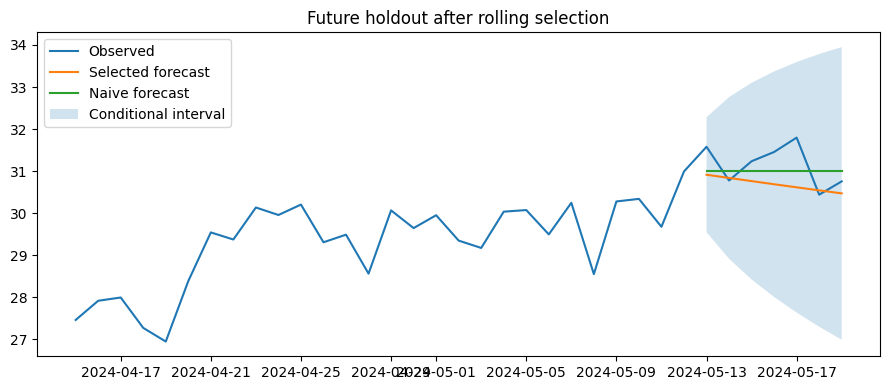

{'test_metrics': {'selected': {'rmse': 0.6263187559555745,
   'mae': 0.5050125646973669,
   'r2': -0.8285879026309131},
  'baseline': {'rmse': 0.4888562299157865,
   'mae': 0.4430355594571428,
   'r2': -0.11400545050359101},
  'mase_denominator': 0.5545701525636364,
  'mase': 0.9106378379053084},
 'test_indices': [133, 134, 135, 136, 137, 138, 139],
 'truth': [31.579006609,
  30.7766736608,
  31.2351961086,
  31.4551710628,
  31.7974617812,
  30.4401911861,
  30.756507539],
 'predictions': [30.91474730015943,
  30.838311942557578,
  30.762894449197105,
  30.68848126551837,
  30.61505901746328,
  30.54261450907164,
  30.471134720109465],
 'baseline_predictions': [30.9922142595,
  30.9922142595,
  30.9922142595,
  30.9922142595,
  30.9922142595,
  30.9922142595,
  30.9922142595],
 'interval_lower': [29.54689098508612,
  28.916707976749432,
  28.42496752986655,
  28.00662980416363,
  27.63628780439406,
  27.30079978940723,
  26.992290391562083],
 'interval_upper': [32.28260361523274,
  32

In [16]:
ctx.run('3-4','ts_final')